# 02 · The variance risk premium: stylised facts
Target: $VRP_t = \sigma^{MFIV}_t - \sigma^{YZ}_{(t, t+21]}$, with $\sigma^{MFIV}$ = VIX/100 (the VIX *is* the 30-day model-free implied vol, i.e. the square root of a replicated variance swap) and Yang-Zhang realised vol over the next 21 sessions.

In [1]:
from pathlib import Path
import pandas as pd
from vrp import data, features, models, backtest, plots

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
pd.set_option("display.precision", 4)

In [2]:
raw = data.load_raw(RAW)
feats = features.build_features(raw["underlying"], raw["chain"], raw["macro"])
print(f"{len(feats)} sessions, {len(features.feature_columns(feats))} predictors")
feats["target"].describe()

2011 sessions, 22 predictors


count    1990.0000
mean        0.0495
std         0.0724
min        -0.4858
25%         0.0283
50%         0.0550
75%         0.0829
max         0.3196
Name: target, dtype: float64

In [3]:
t = feats.dropna(subset=["target"])
print(f"VRP > 0 on {100 * (t.target > 0).mean():.1f}% of days")
t.groupby(t["date"].dt.year)["target"].agg(["mean", "std", lambda s: (s > 0).mean()]).rename(columns={"<lambda_0>": "share_positive"})

VRP > 0 on 87.4% of days


,mean,std,share_positive
date,,,
2018,0.0197,0.0580,0.6773
2019,0.0502,0.0345,0.8730
2020,0.0604,0.1492,0.8617
2021,0.0822,0.0416,0.9722
2022,0.0534,0.0475,0.8924
2023,0.0544,0.0252,1.0000
2024,0.0359,0.0468,0.8651
2025,0.0383,0.0775,0.8515


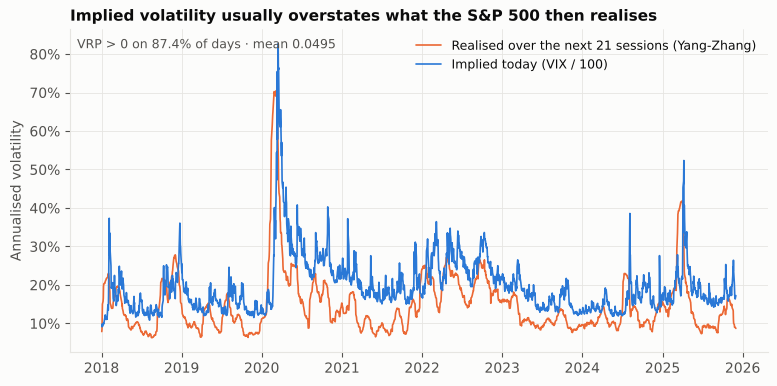

In [4]:
fig = plots.vrp_timeseries(feats)

The premium is persistent but its distribution is left-skewed: it turns sharply negative when realised vol spikes faster than implied (Feb 2018, Feb–Mar 2020). Those are the episodes that define the risk of selling it.

In [5]:
t.nsmallest(5, "target")[["date", "mfiv", "rv_yz_forward", "target"]]

,date,mfiv,rv_yz_forward,target
535,2020-02-19,0.1438,0.6296,-0.4858
536,2020-02-20,0.1556,0.6409,-0.4853
537,2020-02-21,0.1708,0.6490,-0.4782
534,2020-02-18,0.1483,0.6149,-0.4666
533,2020-02-14,0.1368,0.5768,-0.4400
